## Datos históricos de las acciones

Descarga los precios de cierre de AAPL, MSFT, NVDA, META y AMZN durante 2025.

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tickers = ['AAPL', 'MSFT', 'NVDA', 'META', 'AMZN']

prices = yf.download(tickers, start='2025-01-01', end='2026-01-01')['Close']
prices

C:\Users\1\AppData\Local\Temp\ipykernel_1832\1122205255.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start='2025-01-01', end='2026-01-01')['Close']
[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,AMZN,META,MSFT,NVDA
Date,,,,,
2025-01-02,242.093124,220.220001,595.822388,412.895355,137.949387
2025-01-03,241.606644,224.190002,601.181702,417.600586,144.093307
2025-01-06,243.234833,227.610001,626.605896,422.039459,149.040390
2025-01-07,240.464951,222.110001,614.366150,416.633881,139.774597
2025-01-08,240.951416,222.130005,607.236938,418.794159,139.744690
...,...,...,...,...,...
2025-12-24,273.066711,232.380005,665.835815,484.943390,188.169678
2025-12-26,272.657837,232.520004,661.586792,484.635376,190.085205
2025-12-29,273.016876,232.070007,656.998657,484.029236,187.780594


## Estimación de rendimientos y volatilidad

Calcula los rendimientos logarítmicos y estima parámetros anualizados para la simulación.

In [2]:
log_rets = np.log(prices/prices.shift(1))
mean_rets = log_rets.mean() * 252
volatility = log_rets.std() * np.sqrt(252)
mean_rets, volatility

(Ticker
 AAPL    0.114611
 AMZN    0.047578
 META    0.101066
 MSFT    0.153610
 NVDA    0.302812
 dtype: float64,
 Ticker
 AAPL    0.321634
 AMZN    0.343316
 META    0.377943
 MSFT    0.240706
 NVDA    0.498429
 dtype: float64)

## Precios reales del primer semestre de 2026

Descarga los precios observados entre enero y junio de 2026 para compararlos con las simulaciones.

In [3]:
prices_2026 = yf.download(tickers, start='2026-01-01', end='2026-7-01')['Close']
prices_2026

C:\Users\1\AppData\Local\Temp\ipykernel_1832\2899961229.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices_2026 = yf.download(tickers, start='2026-01-01', end='2026-7-01')['Close']
[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,AMZN,META,MSFT,NVDA
Date,,,,,
2026-01-02,270.274353,226.500000,648.739868,469.958496,188.409119
2026-01-05,266.534546,233.059998,657.098328,469.869080,187.680832
2026-01-06,261.647827,240.929993,658.923645,475.493408,186.802887
2026-01-07,259.623322,241.559998,647.024292,480.422119,188.668503
2026-01-08,258.336823,246.289993,644.401062,475.095886,184.608017
...,...,...,...,...,...
2026-06-24,292.827423,234.270004,557.230225,364.773315,198.777573
2026-06-25,274.912903,227.009995,542.441895,352.167023,195.521225
2026-06-26,283.535461,232.690002,549.816101,372.269196,192.314804


## Simulación Monte Carlo estándar

Genera trayectorias de precios mediante movimiento geométrico browniano.

In [4]:
def create_paths(S0, r, sigma, T, steps, n_paths):
    dt = T / steps
    paths = np.zeros((steps + 1, n_paths))
    paths[0, :] = S0
    for t in range(steps):
        paths[t+1, :] = paths[t, :] * np.exp((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * np.random.normal(0, 1, n_paths))
    return paths

## Simulación Monte Carlo con variables antitéticas

Genera pares de trayectorias con perturbaciones opuestas para reducir la varianza de los estimadores además se estima el precio final con 50 simulaciones.

In [5]:
def create_antithetic_paths(S0, r, sigma, T, steps, n_paths):
    dt = T / steps
    path = np.zeros((steps + 1, n_paths))
    ant_path = np.zeros((steps + 1, n_paths))
    path[0, :] = S0
    ant_path[0, :] = S0

    for t in range(steps):
        z = np.random.normal(0, 1, n_paths)
        drift = (r - 0.5 * sigma**2) * dt
        diffusion = sigma * np.sqrt(dt) * z

        path[t+1, :] = path[t, :] * np.exp(drift + diffusion)
        ant_path[t+1, :] = ant_path[t, :] * np.exp(drift - diffusion)


    return path, ant_path

def create_antithetic_final_price(S0, r, sigma, T, simulations):
    drift = (r - 0.5 * sigma**2) * T
    diffusion = sigma * np.sqrt(T)
    z = np.random.normal(0, 1, simulations)
    Sz = S0 * np.exp(drift + diffusion * z)
    Szneg = S0 * np.exp(drift - diffusion * z)
    return (Sz + Szneg) / 2

## Comparación gráfica de simulaciones y precios reales

Visualiza trayectorias simuladas, precios observados y distribuciones de precios terminales.

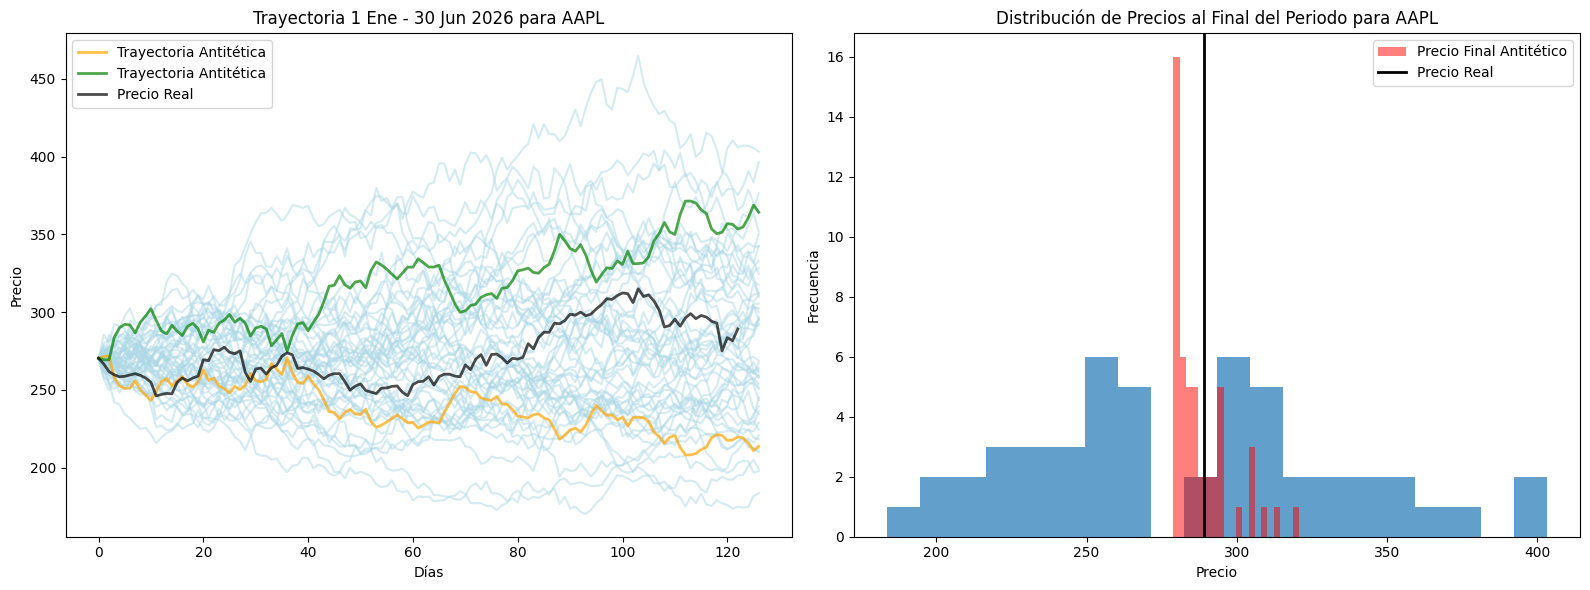

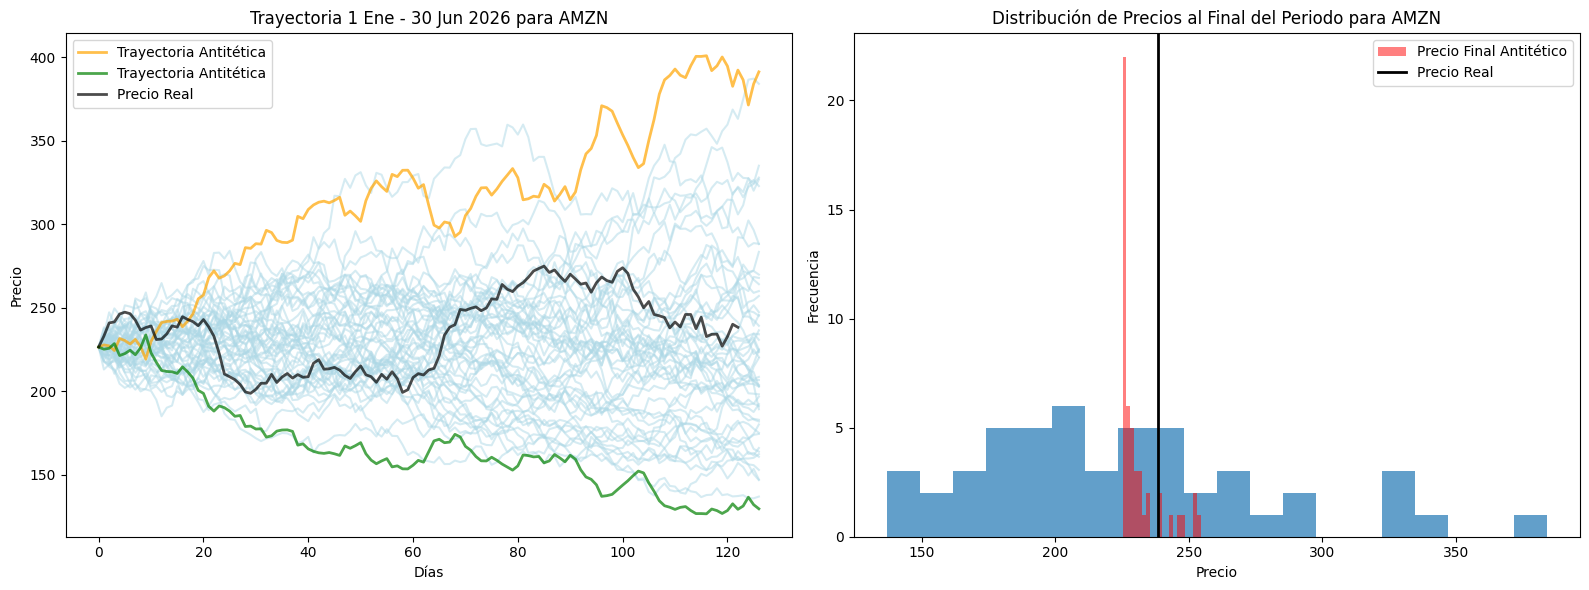

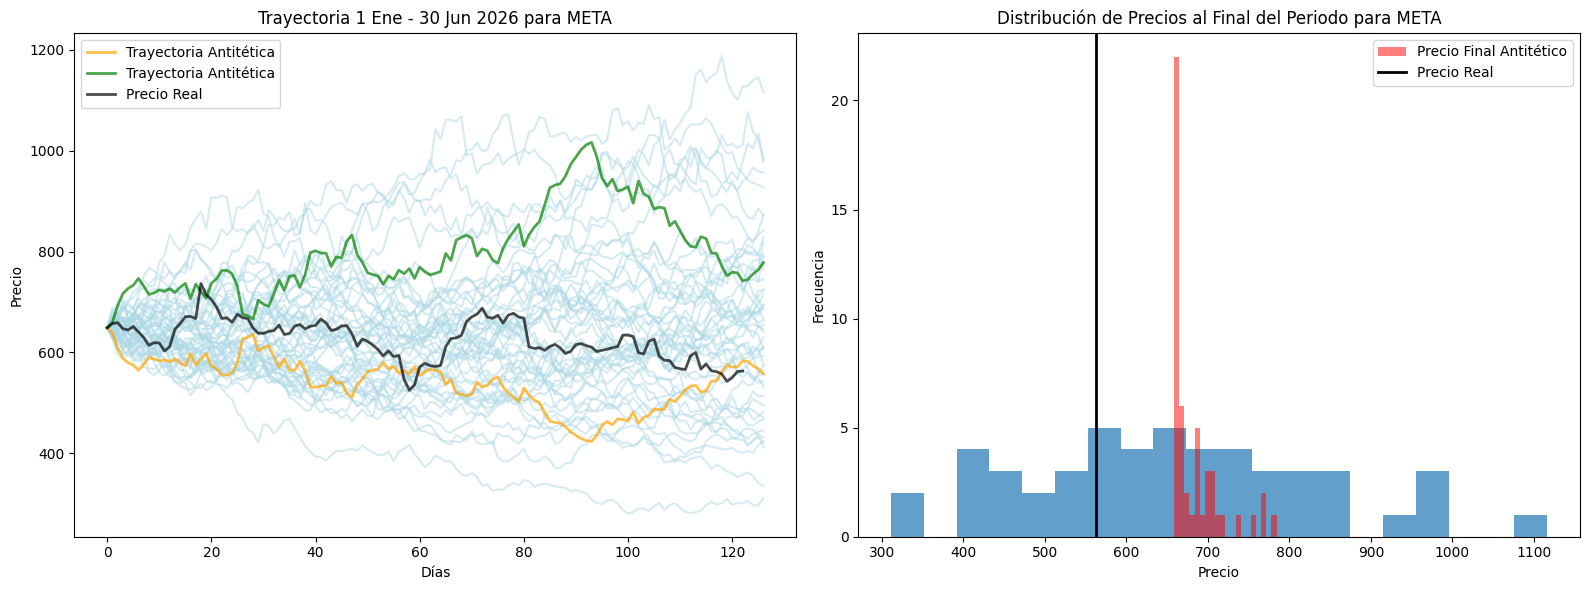

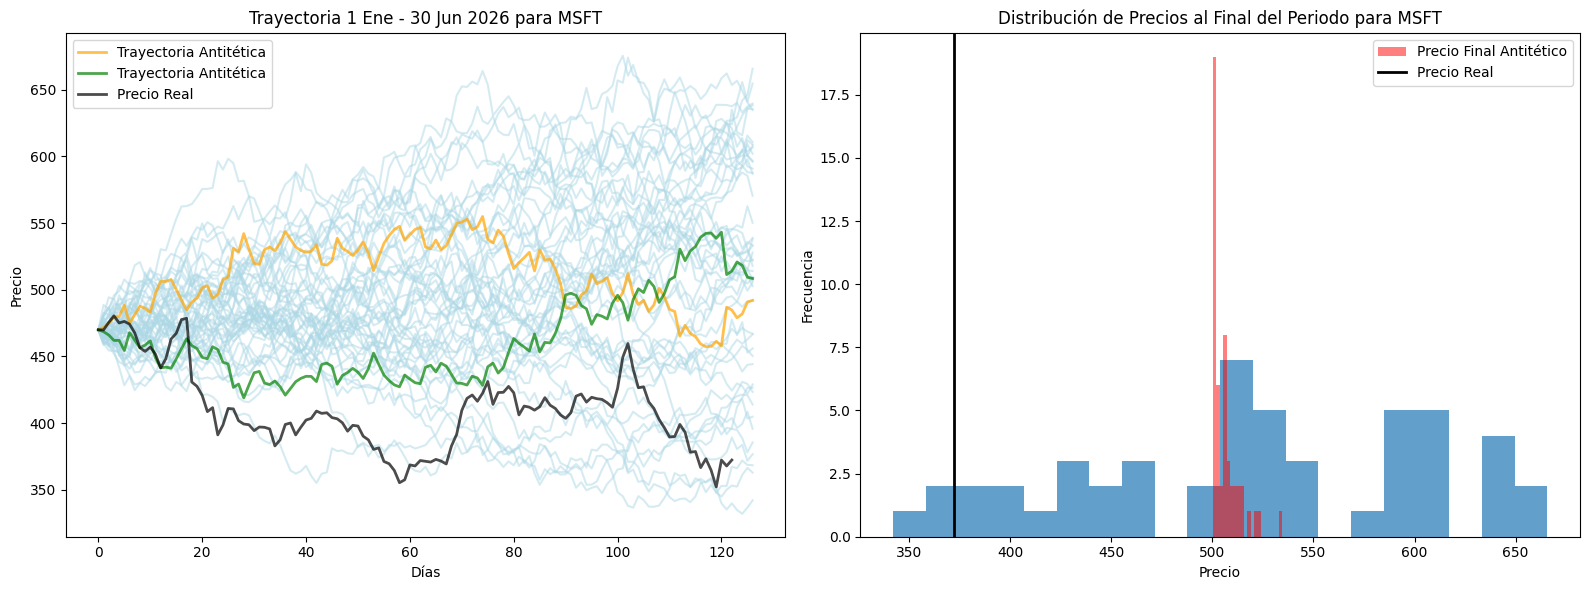

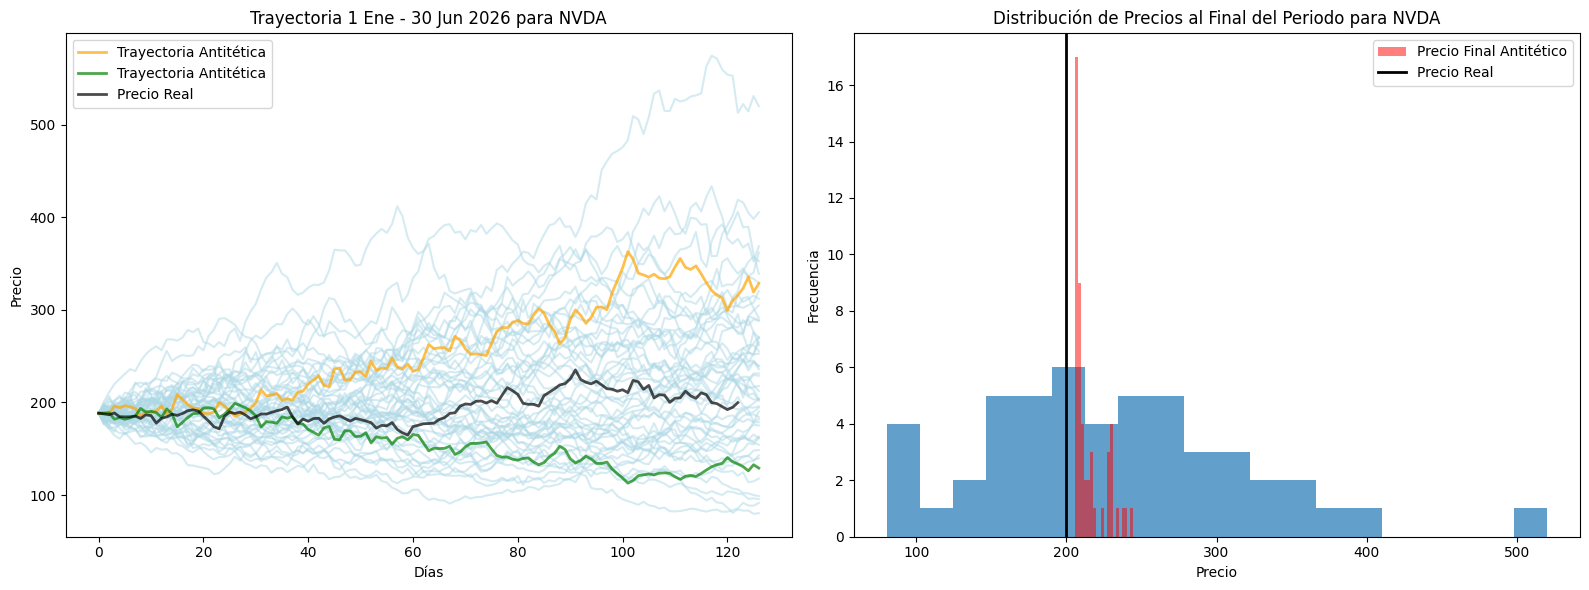

In [6]:
for ticker in prices_2026.columns:
    S0 = prices_2026[ticker].iloc[0]
    r = mean_rets[ticker]
    sigma = volatility[ticker]
    T = 0.5
    steps = 126
    n_paths = 50

    n_path, ant_path = create_antithetic_paths(S0, r, sigma, T, steps, 1)
    paths = create_paths(S0, r, sigma, T, steps, n_paths)
    final_price = create_antithetic_final_price(S0, r, sigma, T, 50)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Trayectorias
    axes[0].plot(paths, color='lightblue', alpha=0.5)
    axes[0].plot(ant_path, color='orange', label='Trayectoria Antitética', linewidth=2, alpha=0.7)
    axes[0].plot(n_path, color='green', linewidth=2, label='Trayectoria Antitética', alpha=0.7)
    axes[0].plot(prices_2026[ticker].values, color='black', linewidth=2, label='Precio Real', alpha=0.7)
    axes[0].set_title(f'Trayectoria 1 Ene - 30 Jun 2026 para {ticker}')
    axes[0].set_xlabel('Días')
    axes[0].set_ylabel('Precio')
    axes[0].legend()

    # Distribución
    axes[1].hist(paths[-1, :], bins=20, alpha=0.7)
    axes[1].hist(final_price, color='red', bins=20, alpha=0.5, label='Precio Final Antitético')
    axes[1].axvline(prices_2026[ticker].iloc[-1], color='black', linewidth=2, label='Precio Real')
    axes[1].set_title(f'Distribución de Precios al Final del Periodo para {ticker}')
    axes[1].set_xlabel('Precio')
    axes[1].set_ylabel('Frecuencia')
    axes[1].legend()

    plt.tight_layout()
    plt.show()